In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy

# WSN Parameters
NUM_NODES = 100
AREA_WIDTH = 100
AREA_HEIGHT = 100
BS_X = 50
BS_Y = 50
INITIAL_ENERGY = 0.5 # Joules

# Radio Model Parameters (First-Order Radio Model)
E_elec = 50e-9  # Energy dissipation for transmitter/receiver electronics (nJ/bit)
E_mp = 0.0013e-12 # Multi-path fading amplifier energy (pJ/bit/m^4)
E_fs = 10e-12    # Free-space amplifier energy (pJ/bit/m^2)
d_0 = np.sqrt(E_fs / E_mp) # Threshold distance

# Generate random node deployments
np.random.seed(42)
x_coords = np.random.rand(NUM_NODES) * AREA_WIDTH
y_coords = np.random.rand(NUM_NODES) * AREA_HEIGHT
node_energies = np.ones(NUM_NODES) * INITIAL_ENERGY

nodes = np.column_stack((x_coords, y_coords))
base_station = np.array([BS_X, BS_Y])

In [2]:
def calculate_distance(p1, p2):
    return np.linalg.norm(p1 - p2)

def compute_energy_cost(cluster_heads_indices, nodes, base_station):
    """
    Evaluates a candidate solution (set of selected Cluster Heads)
    returns total energy cost. Lower is better.
    """
    if len(cluster_heads_indices) == 0:
        return float('inf')

    total_energy = 0
    # Assign each non-CH node to its nearest CH
    for idx, node in enumerate(nodes):
        if idx in cluster_heads_indices:
            continue

        # Find closest CH
        min_dist = float('inf')
        for ch_idx in cluster_heads_indices:
            dist = calculate_distance(node, nodes[ch_idx])
            if dist < min_dist:
                min_dist = dist

        # Energy spent by non-CH sending 4000 bits data
        k = 4000
        if min_dist < d_0:
            e_tx = k * E_elec + k * E_fs * (min_dist ** 2)
        else:
            e_tx = k * E_elec + k * E_mp * (min_dist ** 4)
        total_energy += e_tx

    # Energy spent by CHs receiving from cluster members and sending to BS
    for ch_idx in cluster_heads_indices:
        ch_node = nodes[ch_idx]
        dist_to_bs = calculate_distance(ch_node, base_station)
        k = 4000

        # RX energy assumed for simplicity (receiving data from a few average nodes)
        e_rx = (NUM_NODES / len(cluster_heads_indices)) * k * E_elec

        # TX to Base Station
        if dist_to_bs < d_0:
            e_tx_bs = k * E_elec + k * E_fs * (dist_to_bs ** 2)
        else:
            e_tx_bs = k * E_elec + k * E_mp * (dist_to_bs ** 4)

        total_energy += (e_rx + e_tx_bs)

    return total_energy

In [3]:
def gwo_clustering(nodes, base_station, num_ch=10, max_iter=50, pop_size=15):
    """
    Grey Wolf Optimizer for finding the optimal 'num_ch' cluster heads
    """
    dim = num_ch
    # Initialize populations. Each search agent represents indices of nodes chosen as CHs.
    # Continuous representation mapped to closest discrete node index
    Alpha_pos = np.zeros(dim)
    Alpha_score = float("inf")

    Beta_pos = np.zeros(dim)
    Beta_score = float("inf")

    Delta_pos = np.zeros(dim)
    Delta_score = float("inf")

    # Randomly initialize positions in the range of [0, NUM_NODES - 1]
    Positions = np.random.uniform(0, NUM_NODES - 1, (pop_size, dim))

    # Optimization Loop
    for l in range(max_iter):
        for i in range(pop_size):
            # Ensure bounds & discretize to unique node indices
            Positions[i] = np.clip(Positions[i], 0, NUM_NODES - 1)
            ch_candidate = np.unique(np.round(Positions[i]).astype(int))

            # If duplication reduced the count, pad randomly
            while len(ch_candidate) < dim:
                extra = np.random.randint(0, NUM_NODES, dim - len(ch_candidate))
                ch_candidate = np.unique(np.concatenate([ch_candidate, extra]))

            ch_candidate = ch_candidate[:dim]

            # Compute objective function value
            fitness = compute_energy_cost(ch_candidate, nodes, base_station)

            # Update Alpha, Beta, and Delta
            if fitness < Alpha_score:
                Alpha_score = fitness
                Alpha_pos = Positions[i].copy()

            if fitness > Alpha_score and fitness < Beta_score:
                Beta_score = fitness
                Beta_pos = Positions[i].copy()

            if fitness > Alpha_score and fitness > Beta_score and fitness < Delta_score:
                Delta_score = fitness
                Delta_pos = Positions[i].copy()

        a = 2 - l * (2 / max_iter)  # 'a' decreases linearly from 2 to 0

        # Update positions
        for i in range(pop_size):
            for j in range(dim):
                r1 = np.random.rand()
                r2 = np.random.rand()

                A1 = 2 * a * r1 - a
                C1 = 2 * r2
                D_alpha = abs(C1 * Alpha_pos[j] - Positions[i, j])
                X1 = Alpha_pos[j] - A1 * D_alpha

                r1 = np.random.rand()
                r2 = np.random.rand()

                A2 = 2 * a * r1 - a
                C2 = 2 * r2
                D_beta = abs(C2 * Beta_pos[j] - Positions[i, j])
                X2 = Beta_pos[j] - A2 * D_beta

                r1 = np.random.rand()
                r2 = np.random.rand()

                A3 = 2 * a * r1 - a
                C3 = 2 * r2
                D_delta = abs(C3 * Delta_pos[j] - Positions[i, j])
                X3 = Delta_pos[j] - A3 * D_delta

                Positions[i, j] = (X1 + X2 + X3) / 3

    best_ch = np.unique(np.round(Alpha_pos).astype(int))[:dim]
    return best_ch, Alpha_score

Optimal Cluster Heads Selected: [13 18 31 35 42 48 62 93]
Optimized Total Energy Cost: 0.041457 Joules


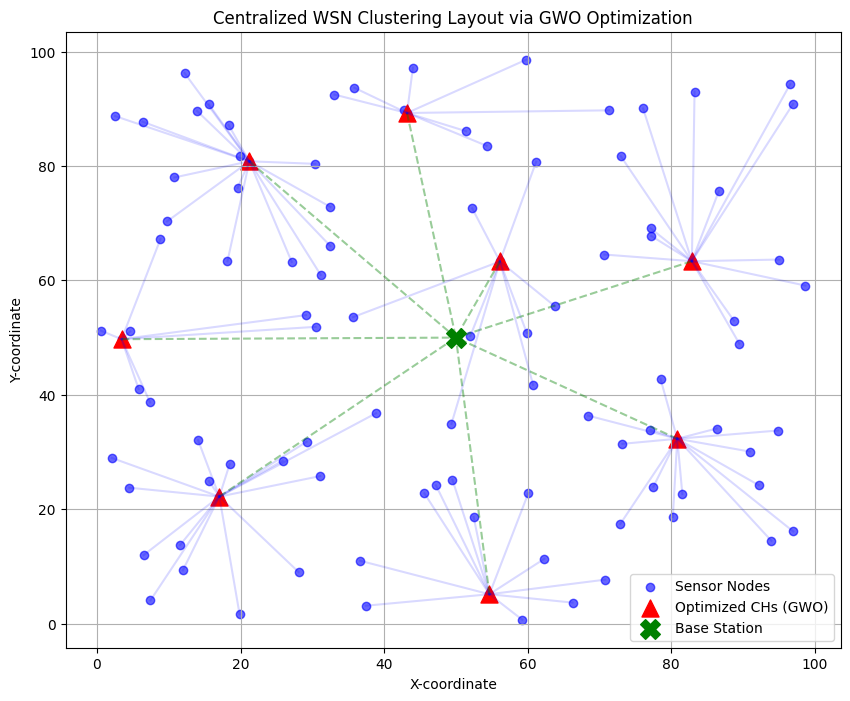

In [4]:
# Run the GWO clustering model
best_cluster_heads, best_fitness = gwo_clustering(nodes, base_station, num_ch=8, max_iter=80, pop_size=20)

print(f"Optimal Cluster Heads Selected: {best_cluster_heads}")
print(f"Optimized Total Energy Cost: {best_fitness:.6f} Joules")

# Visualization of results
plt.figure(figsize=(10, 8))
plt.scatter(nodes[:, 0], nodes[:, 1], c='blue', label='Sensor Nodes', alpha=0.6)
plt.scatter(nodes[best_cluster_heads, 0], nodes[best_cluster_heads, 1], c='red', marker='^', s=150, label='Optimized CHs (GWO)')
plt.scatter(base_station[0], base_station[1], c='green', marker='X', s=200, label='Base Station')

# Draw links to CHs
for idx, node in enumerate(nodes):
    if idx in best_cluster_heads:
        plt.plot([node[0], base_station[0]], [node[1], base_station[1]], 'g--', alpha=0.4)
    else:
        # Find closest CH
        min_dist = float('inf')
        closest_ch = None
        for ch_idx in best_cluster_heads:
            dist = calculate_distance(node, nodes[ch_idx])
            if dist < min_dist:
                min_dist = dist
                closest_ch = nodes[ch_idx]
        plt.plot([node[0], closest_ch[0]], [node[1], closest_ch[1]], 'b-', alpha=0.15)

plt.title('Centralized WSN Clustering Layout via GWO Optimization')
plt.xlabel('X-coordinate')
plt.ylabel('Y-coordinate')
plt.legend()
plt.grid(True)
plt.show()